<a href="https://colab.research.google.com/github/baranichinnasamy/-Transformer-Based-Next-Token-Prediction/blob/main/Transformer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import re
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import Model
from tensorflow.keras.layers import (
    Input, Embedding, Dense, LayerNormalization,
    MultiHeadAttention, Dropout, Add
)

np.random.seed(42)
tf.random.set_seed(42)

text = """
artificial intelligence helps people solve problems.
machine learning learns patterns from data.
deep learning uses neural networks.
a neural network learns from examples.
artificial intelligence can analyze images.
machine learning can predict useful outcomes.
transformers use attention to process text.
self attention learns relationships between tokens.
a model learns patterns from training data.
deep learning can understand complex patterns.
data science uses statistics and machine learning.
neural networks learn useful representations.
computers process information using algorithms.
language models learn patterns from text.
artificial intelligence helps solve difficult problems.
transformers predict the next token using context.
"""

# Basic word-level tokenization
tokens = re.findall(r"\b\w+\b|[^\w\s]", text.lower())

vocabulary = sorted(set(tokens))

# Reserve token ID 0 for padding
word_to_id = {
    word: index + 1
    for index, word in enumerate(vocabulary)
}

id_to_word = {
    index: word
    for word, index in word_to_id.items()
}

token_ids = [word_to_id[word] for word in tokens]
vocab_size = len(word_to_id) + 1

print("Total tokens:", len(token_ids))
print("Vocabulary size:", vocab_size)
print("Vocabulary:", vocabulary)


Total tokens: 111
Vocabulary size: 57
Vocabulary: ['.', 'a', 'algorithms', 'analyze', 'and', 'artificial', 'attention', 'between', 'can', 'complex', 'computers', 'context', 'data', 'deep', 'difficult', 'examples', 'from', 'helps', 'images', 'information', 'intelligence', 'language', 'learn', 'learning', 'learns', 'machine', 'model', 'models', 'network', 'networks', 'neural', 'next', 'outcomes', 'patterns', 'people', 'predict', 'problems', 'process', 'relationships', 'representations', 'science', 'self', 'solve', 'statistics', 'text', 'the', 'to', 'token', 'tokens', 'training', 'transformers', 'understand', 'use', 'useful', 'uses', 'using']


In [ ]:

sequence_length = 6

X = []
y = []

for i in range(len(token_ids) - sequence_length):
    input_sequence = token_ids[i:i + sequence_length]
    target_sequence = token_ids[i + 1:i + sequence_length + 1]

    X.append(input_sequence)
    y.append(target_sequence)

X = np.array(X, dtype=np.int32)
y = np.array(y, dtype=np.int32)

print("Input shape:", X.shape)
print("Target shape:", y.shape)

print("\nExample input:")
print([id_to_word[i] for i in X[0]])

print("\nExample target:")
print([id_to_word[i] for i in y[0]])


Input shape: (105, 6)
Target shape: (105, 6)

Example input:
['artificial', 'intelligence', 'helps', 'people', 'solve', 'problems']

Example target:
['intelligence', 'helps', 'people', 'solve', 'problems', '.']


In [ ]:

embedding_dim = 64
num_heads = 1
feed_forward_dim = 128

# Input token IDs
token_input = Input(shape=(sequence_length,), dtype="int32")

# Token embeddings
token_embedding = Embedding(
    input_dim=vocab_size,
    output_dim=embedding_dim
)(token_input)

# Positional embeddings
position_ids = tf.range(sequence_length)

position_embedding = Embedding(
    input_dim=sequence_length,
    output_dim=embedding_dim
)(position_ids)

# Combine token and position information
x = Add()([token_embedding, position_embedding])

# Causal self-attention
attention_output = MultiHeadAttention(
    num_heads=num_heads,
    key_dim=embedding_dim
)(
    query=x,
    value=x,
    key=x,
    use_causal_mask=True
)

# Residual connection
x = Add()([x, attention_output])
x = LayerNormalization()(x)

# Feed-forward network
ffn_output = Dense(
    feed_forward_dim,
    activation="relu"
)(x)

ffn_output = Dense(embedding_dim)(ffn_output)

# Another residual connection
x = Add()([x, ffn_output])
x = LayerNormalization()(x)
x = Dropout(0.1)(x)

# Output scores for every vocabulary token
output = Dense(vocab_size)(x)

transformer = Model(token_input, output)

transformer.compile(
    optimizer="adam",
    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=True
    ),
    metrics=["sparse_categorical_accuracy"]
)

transformer.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 6)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 6, 64)     │      3,648 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (6, 6, 64)        │          0 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (6, 6, 64)        │     16,640 │ add[0][0],        │
│ (MultiHeadAttentio… │                   │            │ add[0][0],        │
│                     │                   │            │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (6, 6, 64)        │          0 │ add[0][0],        │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (6, 6, 64)        │        128 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (6, 6, 128)       │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (6, 6, 64)        │      8,256 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (6, 6, 64)        │          0 │ layer_normalizat… │
│                     │                   │            │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (6, 6, 64)        │        128 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (6, 6, 64)        │          0 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (6, 6, 57)        │      3,705 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 40,825 (159.47 KB)

 Trainable params: 40,825 (159.47 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
import tensorflow as tf
from tensorflow.keras import Model
from tensorflow.keras.layers import Input, Embedding, Dense, LayerNormalization, MultiHeadAttention, Dropout, Add

# Rebuilding the model with corrected positional embedding broadcasting
token_input = Input(shape=(sequence_length,), dtype="int32")

# Token embeddings: shape (batch_size, sequence_length, embedding_dim)
token_embedding = Embedding(
    input_dim=vocab_size,
    output_dim=embedding_dim
)(token_input)

# Corrected Positional embedding creation with explicit dimension expansion for broadcasting
position_ids = tf.range(sequence_length)
position_embedding = Embedding(
    input_dim=sequence_length,
    output_dim=embedding_dim
)(position_ids)

# Expand shape from (sequence_length, embedding_dim) to (1, sequence_length, embedding_dim) for correct broadcasting
position_embedding = tf.expand_dims(position_embedding, axis=0)

# Combine token and position information safely
x = Add()([token_embedding, position_embedding])

# Causal self-attention
attention_output = MultiHeadAttention(
    num_heads=num_heads,
    key_dim=embedding_dim
)(
    query=x,
    value=x,
    key=x,
    use_causal_mask=True
)

# Residual connection
x = Add()([x, attention_output])
x = LayerNormalization()(x)

# Feed-forward network
ffn_output = Dense(
    feed_forward_dim,
    activation="relu"
)(x)

ffn_output = Dense(embedding_dim)(ffn_output)

# Another residual connection
x = Add()([x, ffn_output])
x = LayerNormalization()(x)
x = Dropout(0.1)(x)

# Output scores for every vocabulary token
output = Dense(vocab_size)(x)

transformer = Model(token_input, output)

transformer.compile(
    optimizer="adam",
    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=True
    ),
    metrics=["sparse_categorical_accuracy"]
)

# Train the corrected model
history = transformer.fit(
    X,
    y,
    epochs=150,
    batch_size=16,
    validation_split=0.15,
    shuffle=False,
    verbose=1
)

print("Final training loss:", history.history["loss"][-1])

if "val_loss" in history.history:
    print("Final validation loss:", history.history["val_loss"][-1])

Epoch 1/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 79ms/step - loss: 4.3678 - sparse_categorical_accuracy: 0.0618 - val_loss: 3.9959 - val_sparse_categorical_accuracy: 0.1250
Epoch 2/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 3.1302 - sparse_categorical_accuracy: 0.2566 - val_loss: 3.8705 - val_sparse_categorical_accuracy: 0.1771
Epoch 3/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 2.4437 - sparse_categorical_accuracy: 0.3970 - val_loss: 3.6928 - val_sparse_categorical_accuracy: 0.2500
Epoch 4/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 1.9061 - sparse_categorical_accuracy: 0.5805 - val_loss: 3.5413 - val_sparse_categorical_accuracy: 0.2812
Epoch 5/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 1.5999 - sparse_categorical_accuracy: 0.6330 - val_loss: 3.4334 - val_sparse_categorical_accuracy: 0.2812
Epoch 6/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.3476 - sparse_categorical_accuracy: 0.6704 - val_loss: 3.3818 - val_sparse_categorical_accuracy: 0.2812
Epoch 7/150
6/6 

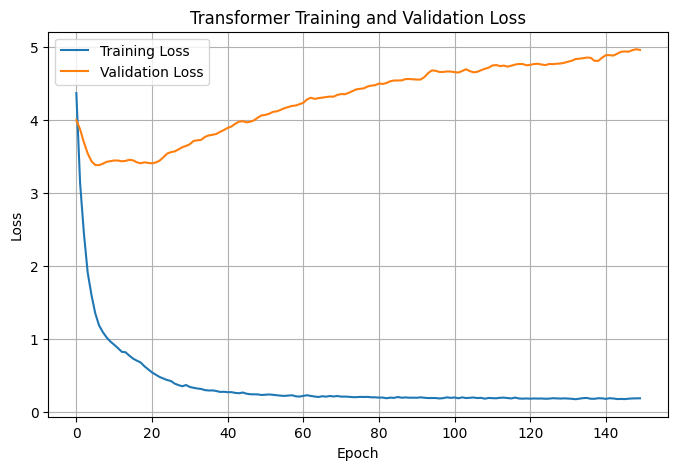

In [ ]:

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Transformer Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:

def predict_next_token(prompt):
    # Tokenize the prompt
    prompt_tokens = re.findall(
        r"\b\w+\b|[^\w\s]",
        prompt.lower()
    )

    # Convert known words to token IDs
    ids = [
        word_to_id[word]
        for word in prompt_tokens
        if word in word_to_id
    ]

    if not ids:
        return "No known tokens found in the prompt."

    # Keep the most recent tokens
    ids = ids[-sequence_length:]

    # Repeat the first known token if the prompt is short.
    # This avoids introducing unseen padding tokens.
    if len(ids) < sequence_length:
        ids = [ids[0]] * (sequence_length - len(ids)) + ids

    input_array = np.array([ids], dtype=np.int32)

    # Get logits at the final position
    logits = transformer.predict(
        input_array,
        verbose=0
    )[0, -1, :]

    # Ignore the reserved padding ID
    logits[0] = -np.inf

    predicted_id = int(np.argmax(logits))

    return id_to_word[predicted_id]


prompt = "artificial intelligence"
prediction = predict_next_token(prompt)

print("Input:", prompt)
print("Predicted next token:", prediction)


Input: artificial intelligence
Predicted next token: can


In [ ]:

def generate_text(prompt, number_of_tokens=10):
    generated = prompt.strip()

    for _ in range(number_of_tokens):
        next_token = predict_next_token(generated)

        if next_token.startswith("No known"):
            break

        # Stop if the model predicts punctuation
        if next_token in [".", ",", "!", "?"]:
            generated += next_token
            if next_token == ".":
                break
        else:
            generated += " " + next_token

    return generated


print(generate_text("artificial intelligence", 10))
print(generate_text("machine learning", 10))
print(generate_text("neural networks", 10))


artificial intelligence can analyze images.
machine learning learns patterns from data.
neural networks.


In [ ]:

loss, accuracy = transformer.evaluate(X, y, verbose=0)

print(f"Token prediction loss: {loss:.4f}")
print(f"Token prediction accuracy: {accuracy * 100:.2f}%")


Token prediction loss: 0.8916
Token prediction accuracy: 82.70%
